<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/Practice_07_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold,
    cross_val_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [4]:
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["target"] = data.target

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["target"] = data.target

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
df.to_csv("/content/breast_cancer.csv", index=False)

from google.colab import files
files.download("/content/breast_cancer.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
print("Размер:", df.shape)
print("\nПропуски:")
print(df.isnull().sum())

print("\nРаспределение классов:")
print(df["target"].value_counts())

display(df.describe())

Размер: (569, 31)

Пропуски:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Распределение классов:
target
1    357
0    212
Name: coun

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


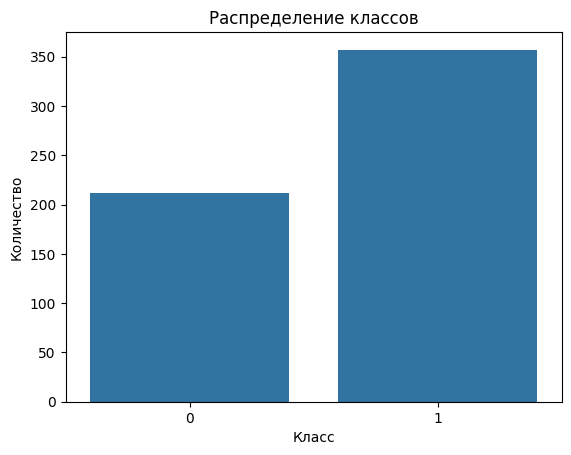

In [8]:
sns.countplot(data=df, x="target")
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.show()

In [9]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


In [10]:
baseline_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_pred
)

baseline_f1 = f1_score(
    y_test, baseline_pred,
    average="macro"
)

print("Accuracy:", round(baseline_accuracy, 4))
print("F1-score:", round(baseline_f1, 4))

Accuracy: 0.9561
F1-score: 0.9526


In [11]:
baseline_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_pred
)

baseline_f1 = f1_score(
    y_test, baseline_pred,
    average="macro"
)

print("Accuracy:", round(baseline_accuracy, 4))
print("F1-score:", round(baseline_f1, 4))

Accuracy: 0.9561
F1-score: 0.9526


In [12]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("Лучший средний CV F1:")
print(round(grid_search.best_score_, 4))

Лучшие параметры:
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Лучший средний CV F1:
0.9603


In [13]:
best_model = grid_search.best_estimator_

best_pred = best_model.predict(X_test)

best_accuracy = accuracy_score(y_test, best_pred)
best_f1 = f1_score(
    y_test, best_pred,
    average="macro"
)

comparison = pd.DataFrame({
    "Модель": [
        "Random Forest Default",
        "Random Forest Tuned"
    ],
    "Accuracy": [
        baseline_accuracy,
        best_accuracy
    ],
    "F1-score": [
        baseline_f1,
        best_f1
    ]
})

display(comparison.round(4))

,Модель,Accuracy,F1-score
0,Random Forest Default,0.9561,0.9526
1,Random Forest Tuned,0.9561,0.9526


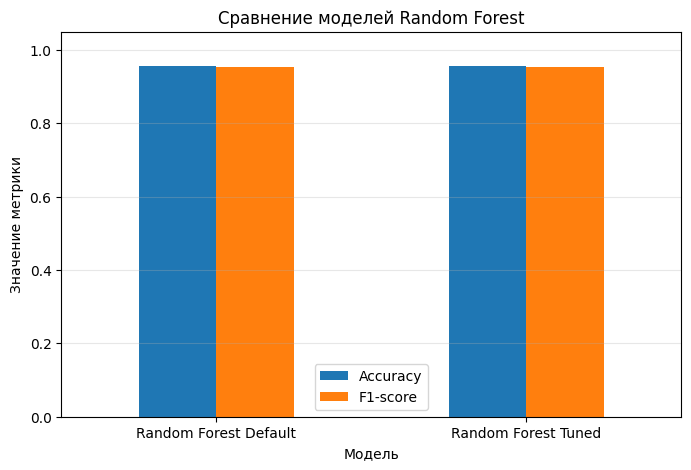

In [14]:
comparison.set_index("Модель").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Сравнение моделей Random Forest")
plt.ylabel("Значение метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



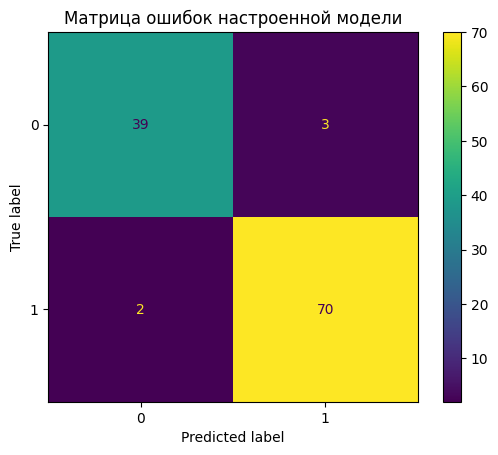

In [15]:
print(classification_report(y_test, best_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred
)

plt.title("Матрица ошибок настроенной модели")
plt.show()

In [16]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
23,worst area,0.140016
27,worst concave points,0.129530
20,worst radius,0.097696
7,mean concave points,0.090885
22,worst perimeter,0.072226
2,mean perimeter,0.069574
0,mean radius,0.068676
6,mean concavity,0.057638
3,mean area,0.049172
26,worst concavity,0.034340


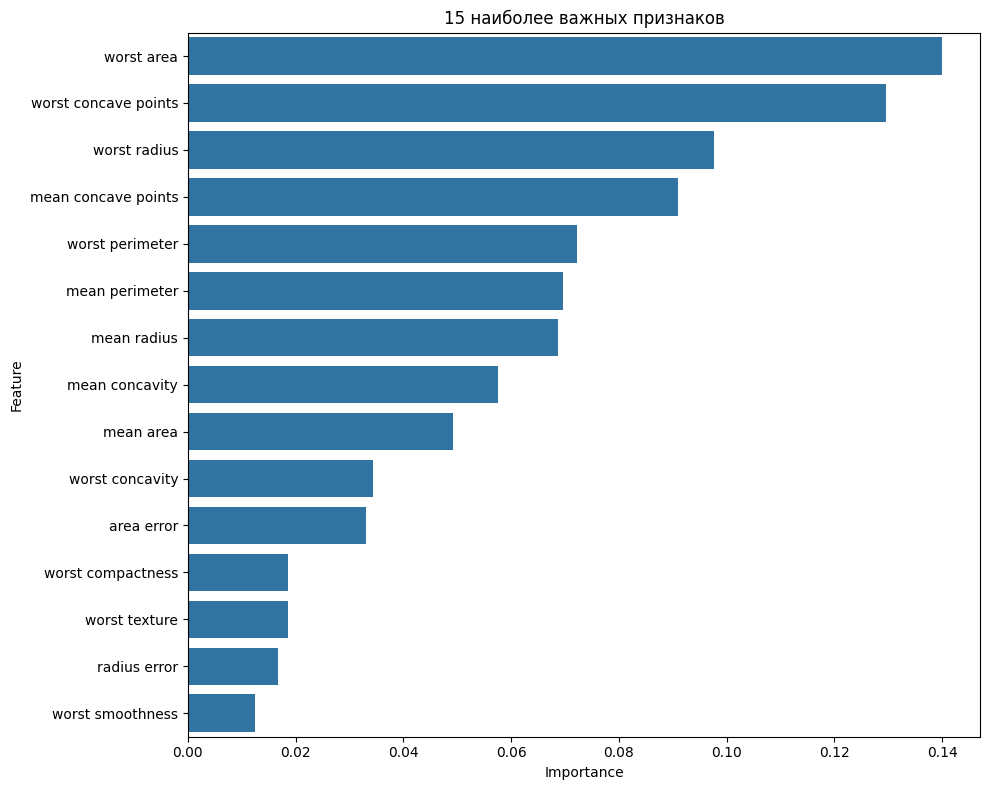

In [17]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("15 наиболее важных признаков")
plt.tight_layout()
plt.show()

In [18]:
selected_counts = [30, 25, 20, 15, 10]

ranked_features = importance_df["Feature"].tolist()

results = []

for count in selected_counts:
    selected_features = ranked_features[:count]

    model = RandomForestClassifier(
        **grid_search.best_params_,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "Количество признаков": count,
        "CV F1-score": scores.mean(),
        "CV Std": scores.std()
    })

feature_results = pd.DataFrame(results)

display(feature_results.round(4))

,Количество признаков,CV F1-score,CV Std
0,30,0.9578,0.0157
1,25,0.9624,0.0169
2,20,0.9578,0.0119
3,15,0.9458,0.0230
4,10,0.9387,0.0251


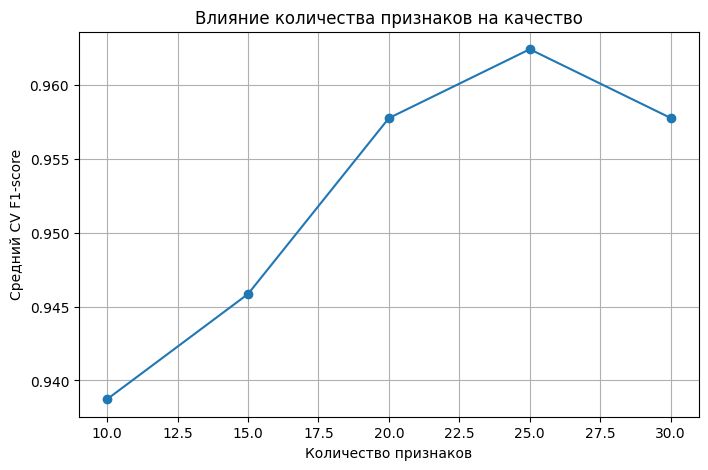

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    feature_results["Количество признаков"],
    feature_results["CV F1-score"],
    marker="o"
)

plt.title("Влияние количества признаков на качество")
plt.xlabel("Количество признаков")
plt.ylabel("Средний CV F1-score")
plt.grid(True)
plt.show()

In [20]:
full_cv_f1 = feature_results.loc[
    feature_results["Количество признаков"] == 30,
    "CV F1-score"
].iloc[0]

eligible = feature_results[
    feature_results["CV F1-score"] >= full_cv_f1 - 0.01
]

best_count = int(
    eligible["Количество признаков"].min()
)

selected_features = ranked_features[:best_count]

reduced_model = RandomForestClassifier(
    **grid_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

reduced_model.fit(
    X_train[selected_features],
    y_train
)

reduced_pred = reduced_model.predict(
    X_test[selected_features]
)

reduced_accuracy = accuracy_score(
    y_test, reduced_pred
)

reduced_f1 = f1_score(
    y_test, reduced_pred,
    average="macro"
)

print("Выбрано признаков:", best_count)
print("Accuracy:", round(reduced_accuracy, 4))
print("F1-score:", round(reduced_f1, 4))

Выбрано признаков: 20
Accuracy: 0.9561
F1-score: 0.9526


In [21]:
final_comparison = pd.DataFrame({
    "Модель": [
        "По умолчанию",
        "Настроенная (30 признаков)",
        f"Сокращённая ({best_count} признаков)"
    ],
    "Accuracy": [
        baseline_accuracy,
        best_accuracy,
        reduced_accuracy
    ],
    "F1-score": [
        baseline_f1,
        best_f1,
        reduced_f1
    ]
})

display(final_comparison.round(4))

,Модель,Accuracy,F1-score
0,По умолчанию,0.9561,0.9526
1,Настроенная (30 признаков),0.9561,0.9526
2,Сокращённая (20 признаков),0.9561,0.9526


In [22]:
removed_features = [
    feature for feature in X.columns
    if feature not in selected_features
]

print("Исключённые признаки:")
print(removed_features)

print("\nРазница F1-score:")
print(round(reduced_f1 - best_f1, 4))

Исключённые признаки:
['mean smoothness', 'mean symmetry', 'mean fractal dimension', 'texture error', 'smoothness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst fractal dimension']

Разница F1-score:
0.0


In [23]:
print("ВЫВОД ПО ПРАКТИЧЕСКОЙ РАБОТЕ №7")

print(
    f"Модель по умолчанию: F1 = {baseline_f1:.4f}"
)

print(
    f"Настроенная модель: F1 = {best_f1:.4f}"
)

print(
    f"Сокращённая модель: F1 = {reduced_f1:.4f}"
)

print(
    f"Количество признаков уменьшено с 30 до {best_count}."
)

if reduced_f1 >= best_f1 - 0.01:
    print(
        "Сокращение признаков не привело к "
        "существенному снижению F1-score "
        "на тестовой выборке (допуск 0.01)."
    )
else:
    print(
        "Сокращение признаков привело к "
        "снижению качества более чем на 0.01."
    )

print("Исключённые признаки:", removed_features)

ВЫВОД ПО ПРАКТИЧЕСКОЙ РАБОТЕ №7
Модель по умолчанию: F1 = 0.9526
Настроенная модель: F1 = 0.9526
Сокращённая модель: F1 = 0.9526
Количество признаков уменьшено с 30 до 20.
Сокращение признаков не привело к существенному снижению F1-score на тестовой выборке (допуск 0.01).
Исключённые признаки: ['mean smoothness', 'mean symmetry', 'mean fractal dimension', 'texture error', 'smoothness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst fractal dimension']


In [24]:
final_comparison.to_csv(
    "/content/model_comparison.csv",
    index=False
)

files.download("/content/model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Практическая работа №7 — Random Forest и важность признаков

## Вариант B

**Тема:** Настройка гиперпараметров случайного леса и анализ важности признаков.

## Цель работы

Настроить гиперпараметры Random Forest с использованием кросс-валидации, сравнить модель с базовой версией и исследовать влияние удаления наименее важных признаков на качество классификации.

## Используемый датасет

Breast Cancer Wisconsin (Diagnostic).

Источник: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

Датасет содержит 569 наблюдений, 30 числовых признаков и целевую переменную с двумя классами.

## Используемые технологии

- Python
- Google Colab
- Pandas и NumPy
- Matplotlib и Seaborn
- Scikit-learn
- RandomForestClassifier
- GridSearchCV

## Выполненные задания

1. Загружен и исследован датасет.
2. Обучена базовая модель Random Forest.
3. Проведён подбор гиперпараметров `n_estimators`, `max_depth`, `min_samples_leaf` с использованием 5-кратной кросс-валидации.
4. Выполнено сравнение базовой и настроенной моделей по Accuracy и F1-score.
5. Построен график важности признаков.
6. Проведён эксперимент с сокращением количества признаков.
7. Обучена сокращённая модель и выполнена проверка на тестовой выборке.
8. Сформулированы выводы о возможности исключения признаков.

## Структура проекта

```text
practice-07-random-forest/
├── data/
│   └── breast_cancer.csv
├── notebooks/
│   └── Practice_07_Random_Forest.ipynb
├── results/
│   └── model_comparison.csv
├── README.md
└── requirements.txt
```

## Запуск проекта

1. Открыть файл `notebooks/Practice_07_Random_Forest.ipynb` в Google Colab.
2. Установить необходимые библиотеки.
3. Запустить все ячейки последовательно.
4. Изучить таблицы, метрики и графики.

## Результаты

В ходе работы сравниваются три модели: базовая, настроенная и сокращённая. Для оценки используются Accuracy и F1-score.

Анализ важности признаков позволяет определить, какие характеристики оказывают наибольшее влияние на предсказания случайного леса.

Эксперимент с удалением признаков помогает оценить, можно ли упростить модель без существенного снижения качества.

## Вывод

В практической работе изучен алгоритм Random Forest и выполнена настройка его гиперпараметров. Использование GridSearchCV позволило подобрать параметры на обучающей выборке. Проведён анализ важности признаков и эксперимент по их сокращению.

Окончательный вывод о качестве сокращённой модели делается на основании полученных метрик.

**Практическая работа №7. Вариант B.**